In [25]:
# ==========================================================
# STEP 1: Select Forecasting Algorithm
# ==========================================================
# Algorithm Chosen:
# ARIMA (Auto Regressive Integrated Moving Average)

In [2]:
# ==========================================================
# STEP 2: Import Required Libraries
# ==========================================================

# Download stock market data
import yfinance as yf

# Data manipulation and analysis
import pandas as pd

# Mathematical operations
import numpy as np

# Data visualization
import matplotlib.pyplot as plt

# ARIMA forecasting model
from statsmodels.tsa.arima.model import ARIMA

# Performance evaluation metric
from sklearn.metrics import mean_squared_error

In [4]:
# ==========================================================
# STEP 3: Download Historical Stock Dataset
# ==========================================================
# Download Reliance Industries stock data
# Time Period: 2020 - 2025
# Data Source: Yahoo Finance
# ==========================================================

data = yf.download(
    "RELIANCE.NS",
    start="2020-01-01",
    end="2025-01-01",
    auto_adjust=True
)

print("Dataset Downloaded Successfully")

[*********************100%***********************]  1 of 1 completed

Dataset Downloaded Successfully


In [5]:
# ==========================================================
# STEP 4: Display Raw Dataset
# ==========================================================
# Display complete dataset
# ==========================================================

data

Price,Close,High,Low,Open,Volume
Ticker,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS
Date,,,,,
2020-01-01,672.216187,680.008852,670.390532,675.956671,14004468
2020-01-02,683.660278,686.176208,673.284921,673.284921,17710316
2020-01-03,684.484070,686.487896,678.183128,682.636062,20984698
2020-01-06,668.609314,680.365044,667.050769,676.847260,24519177
2020-01-07,678.895630,683.304036,673.952826,676.401934,16683622
...,...,...,...,...,...
2024-12-24,1212.280884,1222.988463,1210.545867,1211.834785,6734917
2024-12-26,1206.133911,1217.188348,1203.853555,1213.767935,10016178


In [6]:
# ==========================================================
# STEP 5: Display First Five Records
# ==========================================================
# Preview first five rows
# ==========================================================

data.head()

Price,Close,High,Low,Open,Volume
Ticker,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS
Date,,,,,
2020-01-01,672.216187,680.008852,670.390532,675.956671,14004468
2020-01-02,683.660278,686.176208,673.284921,673.284921,17710316
2020-01-03,684.484070,686.487896,678.183128,682.636062,20984698
2020-01-06,668.609314,680.365044,667.050769,676.847260,24519177
2020-01-07,678.895630,683.304036,673.952826,676.401934,16683622


In [7]:
# ==========================================================
# STEP 6: Display Last Five Records
# ==========================================================
# Preview last five rows
# ==========================================================

data.tail()

Price,Close,High,Low,Open,Volume
Ticker,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS
Date,,,,,
2024-12-24,1212.280884,1222.988463,1210.545867,1211.834785,6734917
2024-12-26,1206.133911,1217.188348,1203.853555,1213.767935,10016178
2024-12-27,1210.595459,1217.386785,1206.580087,1207.869004,7000397
2024-12-30,1200.333862,1212.726837,1197.756148,1205.985131,8818766
2024-12-31,1205.043213,1208.661986,1195.822913,1197.657049,6405475


In [8]:
# ==========================================================
# STEP 7: Inspect Dataset Structure
# ==========================================================
# Displays:
# - Number of rows
# - Number of columns
# - Data types
# - Non-null values
# ==========================================================

data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1238 entries, 2020-01-01 to 2024-12-31
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   (Close, RELIANCE.NS)   1238 non-null   float64
 1   (High, RELIANCE.NS)    1238 non-null   float64
 2   (Low, RELIANCE.NS)     1238 non-null   float64
 3   (Open, RELIANCE.NS)    1238 non-null   float64
 4   (Volume, RELIANCE.NS)  1238 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 58.0 KB


In [9]:
# ==========================================================
# STEP 8: Check Missing Values
# ==========================================================
# Check missing values in each column
# ==========================================================

data.isnull().sum()

Price   Ticker     
Close   RELIANCE.NS    0
High    RELIANCE.NS    0
Low     RELIANCE.NS    0
Open    RELIANCE.NS    0
Volume  RELIANCE.NS    0
dtype: int64

In [10]:
# ==========================================================
# STEP 9: Display Dataset Dimensions
# ==========================================================
# Shape = (Rows, Columns)
# ==========================================================

print("Dataset Shape:", data.shape)

Dataset Shape: (1238, 5)


In [11]:
# ==========================================================
# STEP 10: Select Closing Price Series
# ==========================================================
# Close price is commonly used for forecasting
# because it represents the final trading price
# of the stock for the day.
# ==========================================================

close_prices = data["Close"]

if isinstance(close_prices, pd.DataFrame):
    close_prices = close_prices.iloc[:,0]

close_prices = close_prices.dropna()

print(close_prices.head())

Date
2020-01-01    672.216187
2020-01-02    683.660278
2020-01-03    684.484070
2020-01-06    668.609314
2020-01-07    678.895630
Name: RELIANCE.NS, dtype: float64


In [12]:
# ==========================================================
# STEP 11: Convert Data to Business-Day Frequency
# ==========================================================
# Yahoo Finance contains only trading days.
#
# Convert data into Business-Day frequency.
#
# Missing dates (weekends/holidays) are filled
# using Forward Fill method.
# ==========================================================

close_prices = close_prices.asfreq('B')

close_prices = close_prices.ffill()

print(close_prices.index.freq)

<BusinessDay>


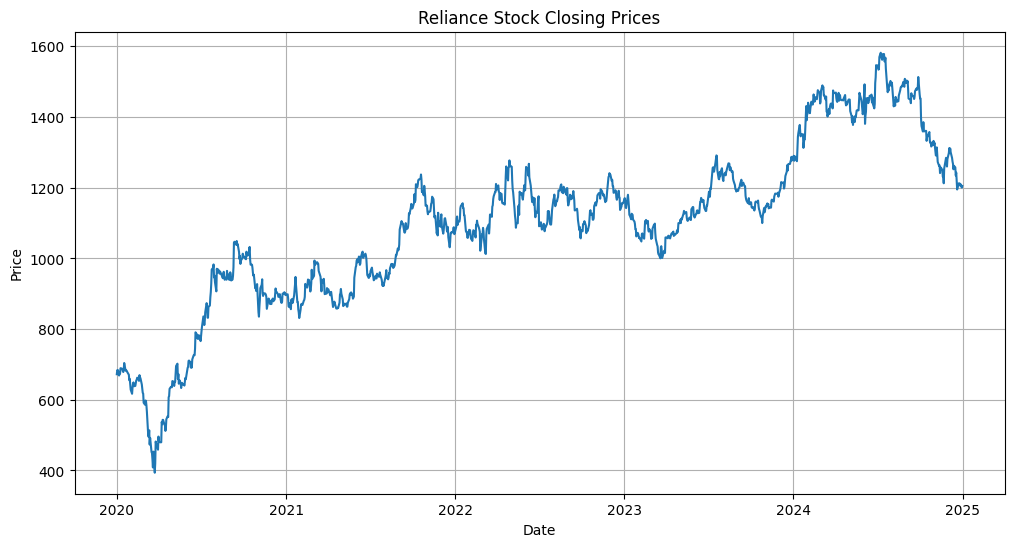

In [13]:
# ==========================================================
# STEP 12: Visualize Historical Stock Prices
# ==========================================================
# Plot historical stock price movement
# ==========================================================

plt.figure(figsize=(12,6))

plt.plot(close_prices)

plt.title("Reliance Stock Closing Prices")

plt.xlabel("Date")

plt.ylabel("Price")

plt.grid(True)

plt.show()

In [14]:
# ==========================================================
# STEP 13: Split Dataset into Training and Testing Sets
# ==========================================================
# 80% Training Data
# 20% Testing Data
# ==========================================================

train_size = int(len(close_prices) * 0.8)

train = close_prices[:train_size]

test = close_prices[train_size:]

print("Training Samples:", len(train))
print("Testing Samples:", len(test))

Training Samples: 1044
Testing Samples: 261


In [16]:
# ==========================================================
# STEP 14: Build ARIMA Model
# ==========================================================
# ARIMA(p,d,q)
#
# p = 5  -> Uses previous 5 observations
# d = 1  -> First-order differencing
# q = 0  -> No moving average component
# ==========================================================

model = ARIMA(train, order=(5,1,0))

In [17]:
# ==========================================================
# STEP 15: Train ARIMA Model
# ==========================================================
# Learn patterns from historical stock prices
# ==========================================================

model_fit = model.fit()

In [18]:
# ==========================================================
# STEP 16: Display Model Summary
# ==========================================================
# Displays:
# - Coefficients
# - AIC
# - BIC
# - Statistical metrics
# ==========================================================

print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:            RELIANCE.NS   No. Observations:                 1044
Model:                 ARIMA(5, 1, 0)   Log Likelihood               -4401.835
Date:                Wed, 16 Sep 2026   AIC                           8815.671
Time:                        12:52:51   BIC                           8845.370
Sample:                    01-01-2020   HQIC                          8826.935
                         - 01-01-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0233      0.030      0.780      0.436      -0.035       0.082
ar.L2          0.0003      0.028      0.011      0.991      -0.055       0.056
ar.L3         -0.0234      0.026     -0.896      0.3

In [19]:
# ==========================================================
# STEP 17: Predict Stock Prices
# ==========================================================
# Forecast stock prices for the testing period
# ==========================================================

predictions = model_fit.forecast(
    steps=len(test)
)

print(predictions.head())

2024-01-02    1279.768066
2024-01-03    1279.975303
2024-01-04    1280.753238
2024-01-05    1280.111405
2024-01-08    1280.238483
Freq: B, Name: predicted_mean, dtype: float64


In [20]:
# ==========================================================
# STEP 18: Calculate RMSE
# ==========================================================
# RMSE measures prediction error.
# Lower RMSE indicates better performance.
# ==========================================================

rmse = np.sqrt(
    mean_squared_error(test, predictions)
)

print("RMSE =", rmse)

RMSE = 155.64200748983095


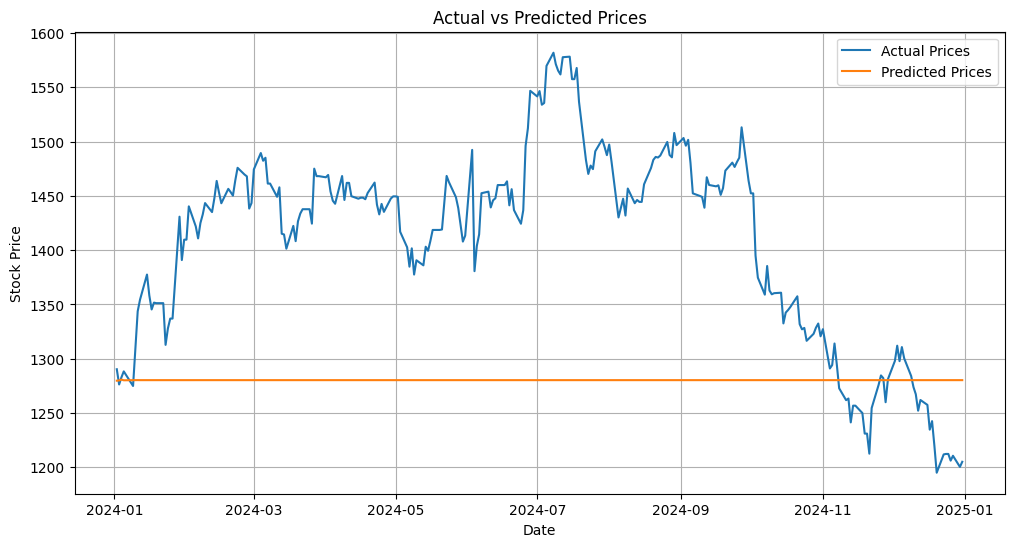

In [21]:
# ==========================================================
# STEP 19: Compare Actual vs Predicted Prices
# ==========================================================
# Compare actual stock prices with ARIMA predictions
# ==========================================================

plt.figure(figsize=(12,6))

plt.plot(
    test.index,
    test,
    label="Actual Prices"
)

plt.plot(
    test.index,
    predictions,
    label="Predicted Prices"
)

plt.title("Actual vs Predicted Prices")

plt.xlabel("Date")

plt.ylabel("Stock Price")

plt.legend()

plt.grid(True)

plt.show()

In [22]:
# ==========================================================
# STEP 20: Forecast Future Stock Prices
# ==========================================================
# Generate stock price forecast
# for the next 30 business days
# ==========================================================

future_predictions = model_fit.forecast(
    steps=30
)

print(future_predictions)

2024-01-02    1279.768066
2024-01-03    1279.975303
2024-01-04    1280.753238
2024-01-05    1280.111405
2024-01-08    1280.238483
2024-01-09    1280.221049
2024-01-10    1280.223856
2024-01-11    1280.284667
2024-01-12    1280.246133
2024-01-15    1280.252945
2024-01-16    1280.250594
2024-01-17    1280.249756
2024-01-18    1280.254204
2024-01-19    1280.251964
2024-01-22    1280.252392
2024-01-23    1280.252189
2024-01-24    1280.252054
2024-01-25    1280.252362
2024-01-26    1280.252233
2024-01-29    1280.252264
2024-01-30    1280.252250
2024-01-31    1280.252236
2024-02-01    1280.252256
2024-02-02    1280.252249
2024-02-05    1280.252251
2024-02-06    1280.252250
2024-02-07    1280.252249
2024-02-08    1280.252250
2024-02-09    1280.252250
2024-02-12    1280.252250
Freq: B, Name: predicted_mean, dtype: float64
